# 02. Credit Risk — классификация

Бинарная классификация: предсказать `loan_status` (0 - кредит возвращён, 1 - дефолт).

**Датасет:** 32 581 * 12.

**Дисбаланс классов:** 78.2 / 21.8.

**План:**
1. Препроцессинг: выбросы, пропуски, кодирование категориальных.
2. Train/test split со стратификацией.
3. Baseline - логистическая регрессия.
4. Кросс-валидация StratifiedKFold(5).
5. Прогон 9 моделей на едином протоколе.
6. Таблица результатов + bar plot.

In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import warnings

from config import Config

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

config = Config()
RANDOM_STATE = config.RANDOM_STATE
print(config)

Config(mode='local', credit='C:\\Users\\ikr\\PycharmProjects\\classification-regression-tabular-review\\data\\credit_risk_dataset.csv', churn='C:\\Users\\ikr\\PycharmProjects\\classification-regression-tabular-review\\data\\WA_Fn-UseC_-Telco-Customer-Churn.csv', demand='C:\\Users\\ikr\\PycharmProjects\\classification-regression-tabular-review\\data\\train.csv', random_state=42)


In [4]:
df_credit = pd.read_csv(config.path_credit)
print("credit:", df_credit.shape)
df_credit.head()

credit: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## Препроцессинг

**Выбросы.** `person_age > 100` и `person_emp_length > 60` - очевидные ошибки ввода, удаляем.

**Пропуски.**

- `person_emp_length` -> медиана **внутри возрастной группы** `age_group`. Стаж зависит от возраста: у 20-летних он 1-3 года, у 50-летних 20-30 лет. Глобальная медиана занизила бы стаж для старших.
- `loan_int_rate` -> медиана **внутри группы** `loan_grade`. Ставка сильно зависит от грейда: у A - 7%, у G - 20%.

**Условное заполнение (conditional imputation)** - заполняем статистикой **внутри группы** (по возрасту, по грейду), а не глобальным средним. Глобальное среднее смешивает неоднородные подгруппы.

**Категориальные.** 4 колонки с кардинальностью ≤ 7 - OneHotEncoder.

**Масштабирование.** StandardScaler для числовых - нужен LogReg, SVM, kNN.

In [5]:
credit = df_credit.copy()

credit = credit[credit['person_age'] <= 100]
credit = credit[credit['person_emp_length'] <= 60]

credit['age_group'] = pd.cut(
    credit['person_age'],
    bins=[0, 25, 35, 45, 60, 100],
    labels=['<25', '25-35', '35-45', '45-60', '60+']
)

credit['person_emp_length'] = credit.groupby('age_group')['person_emp_length'].transform(
    lambda s: s.fillna(s.median())
)

credit = credit.drop(columns=['age_group'])

credit['loan_int_rate'] = credit.groupby('loan_grade')['loan_int_rate'].transform(
    lambda s: s.fillna(s.median())
)

print(f"shape после чистки: {credit.shape}")
print(f"пропуски: {credit.isna().sum().sum()}")

shape после чистки: (31679, 12)
пропуски: 0


## Train / test split

`X` - матрица признаков, `y` - вектор таргета.

`stratify=y` сохраняет пропорцию классов 78/22 в обоих наборах.

`random_state=42` фиксирует разбиение - воспроизводимость.

In [6]:
from sklearn.model_selection import train_test_split


X = credit.drop(columns=['loan_status'])
y = credit['loan_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"train: {X_train.shape}, test: {X_test.shape}")
print(f"доля класса 1 в train: {y_train.mean():.4f}")
print(f"доля класса 1 в test:  {y_test.mean():.4f}")

train: (25343, 11), test: (6336, 11)
доля класса 1 в train: 0.2154
доля класса 1 в test:  0.2154


## Препроцессор + baseline

**`Pipeline`** - цепочка «препроцессинг -> модель». Внутри CV препроцессор учится **только на train** каждого фолда -> нет утечки.

**`ColumnTransformer`** - разные ветки для разных типов колонок:
- `StandardScaler` к числовым;
- `OneHotEncoder` к категориальным.

**LogisticRegression** - baseline. Если сложная модель не бьёт LogReg - что-то не так.

**Метрики:** ROC-AUC (основная), F1, Precision, Recall.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, classification_report


cat_cols = X.select_dtypes(include=['object', 'str']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'str']).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

pipe_logreg = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

pipe_logreg.fit(X_train, y_train)
y_proba = pipe_logreg.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
print(f"F1:      {f1_score(y_test, y_pred):.4f}")
print()
print(classification_report(y_test, y_pred))

ROC-AUC: 0.8747
F1:      0.6500

              precision    recall  f1-score   support

           0       0.89      0.95      0.92      4971
           1       0.77      0.56      0.65      1365

    accuracy                           0.87      6336
   macro avg       0.83      0.76      0.79      6336
weighted avg       0.86      0.87      0.86      6336



## Кросс-валидация baseline

**StratifiedKFold(5)** - данные делятся на 5 фолдов с сохранением пропорции классов.

`cross_val_score` обучает модель 5 раз, возвращает массив метрик.

`± std` важнее среднего: если std большое - модель нестабильна.

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_score


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scores = cross_val_score(
    pipe_logreg, X, y,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

print(f"ROC-AUC по фолдам: {scores.round(4)}")
print(f"Среднее: {scores.mean():.4f} ± {scores.std():.4f}")

ROC-AUC по фолдам: [0.872  0.87   0.8698 0.8651 0.8741]
Среднее: 0.8702 ± 0.0030


## Сравнение 9 моделей

Прогоняем 9 моделей на **том же** препроцессоре и том же CV:

- **Линейные:** LogReg
- **Деревья:** DecisionTree
- **Бэггинг:** RandomForest
- **Бустинг:** XGBoost, LightGBM, CatBoost
- **Метрические:** kNN
- **Margin:** SVM (rbf)
- **Вероятностные:** NaiveBayes

Порядок моделей в словаре - от простых к сложным.

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB


models = {
    'LogReg':       LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'DecisionTree': DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    'RandomForest': RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
    'XGBoost':      XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                  eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1),
    'LightGBM':     LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                   random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
    'CatBoost':     CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,
                                       random_state=RANDOM_STATE, verbose=0),
    'kNN':          KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    'SVM':          SVC(kernel='rbf', C=1.0, probability=True, random_state=RANDOM_STATE),
    'NaiveBayes':   GaussianNB(),
}

results = {}

for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    scores = cross_val_score(pipe, X, y, cv=cv, scoring='roc_auc', n_jobs=-1)
    results[name] = (scores.mean(), scores.std())
    print(f"{name:15} ROC-AUC: {scores.mean():.4f} ± {scores.std():.4f}")

LogReg          ROC-AUC: 0.8702 ± 0.0030
DecisionTree    ROC-AUC: 0.9096 ± 0.0072
RandomForest    ROC-AUC: 0.9325 ± 0.0036
XGBoost         ROC-AUC: 0.9498 ± 0.0032
LightGBM        ROC-AUC: 0.9491 ± 0.0040
CatBoost        ROC-AUC: 0.9418 ± 0.0040
kNN             ROC-AUC: 0.8854 ± 0.0050
SVM             ROC-AUC: 0.8990 ± 0.0038
NaiveBayes      ROC-AUC: 0.8317 ± 0.0041


## Таблица результатов

Сортировка по среднему ROC-AUC, убывание.

In [10]:
results_df = (
    pd.DataFrame(results, index=['mean', 'std'])
      .T
      .sort_values('mean', ascending=False)
)
print(results_df)

print()
print("Модели в results:", list(results.keys()))
print("Всего:", len(results))

                  mean       std
XGBoost       0.949773  0.003179
LightGBM      0.949096  0.003987
CatBoost      0.941829  0.004038
RandomForest  0.932546  0.003592
DecisionTree  0.909568  0.007162
SVM           0.899041  0.003784
kNN           0.885421  0.004982
LogReg        0.870217  0.002995
NaiveBayes    0.831726  0.004079

Модели в results: ['LogReg', 'DecisionTree', 'RandomForest', 'XGBoost', 'LightGBM', 'CatBoost', 'kNN', 'SVM', 'NaiveBayes']
Всего: 9


## Bar plot

Топ-3 - зелёным, остальные - синим.

Усы (yerr) - стандартное отклонение по 5 фолдам.

Пунктирная линия - уровень 0.9.

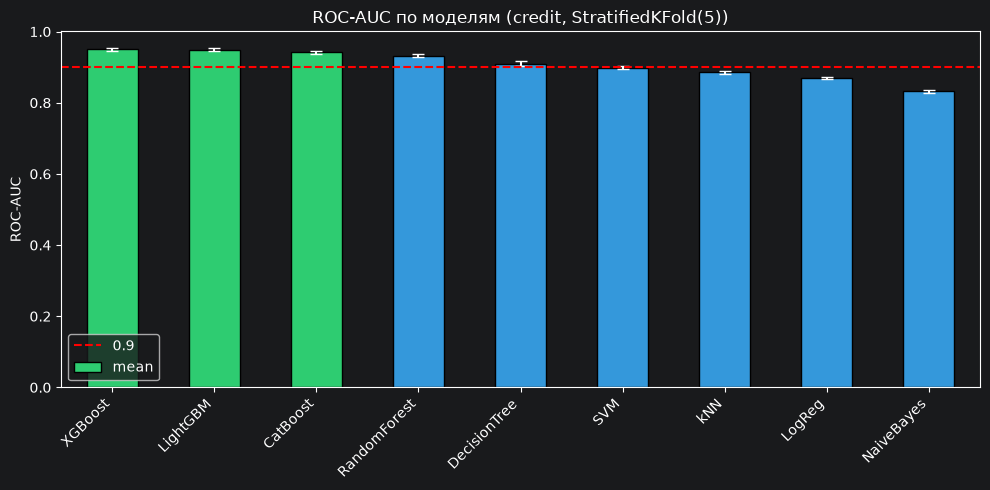

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#2ecc71' if i < 3 else '#3498db' for i in range(len(results_df))]

results_df['mean'].plot(
    kind='bar', yerr=results_df['std'], ax=ax,
    color=colors, capsize=4, edgecolor='black'
)
ax.axhline(0.9, color='red', linestyle='--', label='0.9')
ax.set_title('ROC-AUC по моделям (credit, StratifiedKFold(5))')
ax.set_ylabel('ROC-AUC')
ax.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(config.credit_plot, dpi=150)
plt.show()

## Выводы

1. **Иерархия семейств** подтверждена: бустинг > бэггинг > дерево > линейные.
2. **XGBoost и LightGBM статистически неразличимы** (Δ = 0.0007 << std).
3. **CatBoost отстаёт на 0.007** - вероятно, из-за OneHot вместо нативных категорий.
4. **DecisionTree переобучается** (std = 0.0072 в 2× выше остальных).
5. **NaiveBayes - последний** - нарушено предположение о независимости признаков.
6. **Разрыв топ vs baseline:** +0.080 ROC-AUC.

Препроцессинг и протокол идентичны для churn - сравнение честное.